In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Order_ID                  5000 non-null   object 
 1   Customer_ID               5000 non-null   object 
 2   Date                      5000 non-null   object 
 3   Age                       5000 non-null   int64  
 4   Gender                    5000 non-null   object 
 5   City                      5000 non-null   object 
 6   Product_Category          5000 non-null   object 
 7   Unit_Price                5000 non-null   float64
 8   Quantity                  5000 non-null   int64  
 9   Discount_Amount           5000 non-null   float64
 10  Total_Amount              5000 non-null   float64
 11  Payment_Method            5000 non-null   object 
 12  Device_Type               5000 non-null   object 
 13  Session_Duration_Minutes  5000 non-null   int64  
 14  Pages_Vi

In [8]:
df["Date"]=pd.to_datetime(df["Date"])

In [10]:
df.isna().sum()

Order_ID                    0
Customer_ID                 0
Date                        0
Age                         0
Gender                      0
City                        0
Product_Category            0
Unit_Price                  0
Quantity                    0
Discount_Amount             0
Total_Amount                0
Payment_Method              0
Device_Type                 0
Session_Duration_Minutes    0
Pages_Viewed                0
Is_Returning_Customer       0
Delivery_Time_Days          0
Customer_Rating             0
dtype: int64

In [16]:
for col in df:
    print(col)
    print(df[col].unique())
    print("-"*110)

Order_ID
['ORD_001337' 'ORD_004885' 'ORD_004507' ... 'ORD_003543' 'ORD_004443'
 'ORD_000902']
--------------------------------------------------------------------------------------------------------------
Customer_ID
['CUST_01337' 'CUST_04885' 'CUST_04507' ... 'CUST_03543' 'CUST_04443'
 'CUST_00902']
--------------------------------------------------------------------------------------------------------------
Date
<DatetimeArray>
['2023-01-01 00:00:00', '2023-01-02 00:00:00', '2023-01-03 00:00:00',
 '2023-01-04 00:00:00', '2023-01-05 00:00:00', '2023-01-06 00:00:00',
 '2023-01-07 00:00:00', '2023-01-08 00:00:00', '2023-01-09 00:00:00',
 '2023-01-10 00:00:00',
 ...
 '2024-03-17 00:00:00', '2024-03-18 00:00:00', '2024-03-19 00:00:00',
 '2024-03-20 00:00:00', '2024-03-21 00:00:00', '2024-03-22 00:00:00',
 '2024-03-23 00:00:00', '2024-03-24 00:00:00', '2024-03-25 00:00:00',
 '2024-03-26 00:00:00']
Length: 451, dtype: datetime64[ns]
----------------------------------------------------------

In [18]:
df.duplicated().sum()

0

In [19]:
df.describe()

,Date,Age,Unit_Price,Quantity,Discount_Amount,Total_Amount,Session_Duration_Minutes,Pages_Viewed,Delivery_Time_Days,Customer_Rating
count,5000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.00000,5000.000000,5000.000000
mean,2023-08-16 09:16:24.959999744,35.032600,455.834120,2.220000,24.852804,983.108914,14.57340,8.98420,6.497000,3.902800
min,2023-01-01 00:00:00,18.000000,5.180000,1.000000,0.000000,7.870000,1.00000,1.00000,1.000000,1.000000
25%,2023-04-30 00:00:00,27.000000,76.587500,1.000000,0.000000,122.517500,8.00000,7.00000,4.000000,3.000000
50%,2023-08-17 00:00:00,35.000000,182.950000,2.000000,0.000000,337.910000,13.00000,9.00000,6.000000,4.000000
75%,2023-12-06 00:00:00,42.000000,513.930000,3.000000,8.760000,979.695000,19.00000,11.00000,8.000000,5.000000
max,2024-03-26 00:00:00,75.000000,7159.450000,5.000000,1525.550000,22023.900000,73.00000,24.00000,25.000000,5.000000
std,NaN,11.080546,712.477209,1.398711,88.385124,1898.978528,8.66575,2.80434,3.464966,1.128542


In [20]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month_name()
df["Day"] = df["Date"].dt.day

In [23]:
df

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,...,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating,Year,Month,Day
0,ORD_001337,CUST_01337,2023-01-01,27,Female,Bursa,Toys,54.28,1,0.00,...,Debit Card,Mobile,4,14,True,8,5,2023,January,1
1,ORD_004885,CUST_04885,2023-01-01,42,Male,Konya,Toys,244.90,1,0.00,...,Credit Card,Mobile,11,3,True,3,3,2023,January,1
2,ORD_004507,CUST_04507,2023-01-01,43,Female,Ankara,Food,48.15,5,0.00,...,Credit Card,Mobile,7,8,True,5,2,2023,January,1
3,ORD_000645,CUST_00645,2023-01-01,32,Male,Istanbul,Electronics,804.06,1,229.28,...,Credit Card,Mobile,8,10,False,1,4,2023,January,1
4,ORD_000690,CUST_00690,2023-01-01,40,Female,Istanbul,Sports,755.61,5,0.00,...,Cash on Delivery,Desktop,21,10,True,7,4,2023,January,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,ORD_001048,CUST_01048,2024-03-26,18,Female,Izmir,Beauty,130.35,1,27.30,...,Bank Transfer,Mobile,17,10,False,9,1,2024,March,26
4996,ORD_001051,CUST_01051,2024-03-26,27,Male,Adana,Beauty,71.55,1,0.00,...,Debit Card,Mobile,13,9,True,6,4,2024,March,26
4997,ORD_003543,CUST_03543,2024-03-26,45,Female,Antalya,Food,39.38,1,5.27,...,Digital Wallet,Mobile,38,10,True,5,4,2024,March,26
4998,ORD_004443,CUST_04443,2024-03-26,41,Female,Istanbul,Fashion,171.19,1,0.00,...,Credit Card,Mobile,20,12,True,5,4,2024,March,26


In [24]:
Salesby_cate=df.groupby("Product_Category")["Total_Amount"].sum().sort_values(ascending=False)
print(Salesby_cate)

Product_Category
Electronics      2328806.81
Home & Garden     908348.86
Sports            754563.56
Fashion           375214.93
Toys              223142.48
Beauty            156584.74
Food               96138.67
Books              72744.52
Name: Total_Amount, dtype: float64


In [29]:
disc_by_device=df.groupby("Device_Type")["Discount_Amount"].sum().sort_values(ascending=False)
print(disc_by_device)

Device_Type
Mobile     69323.43
Desktop    43345.51
Tablet     11595.08
Name: Discount_Amount, dtype: float64


In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

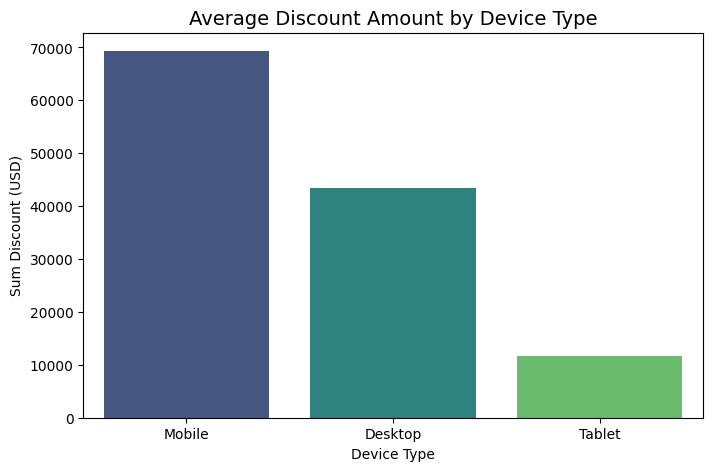

In [31]:
plt.figure(figsize=(8,5))
sns.barplot(x=disc_by_device.index,y=disc_by_device,palette="viridis")
plt.title("Average Discount Amount by Device Type", fontsize=14)
plt.xlabel("Device Type")
plt.ylabel("Sum Discount (USD)")
plt.show()

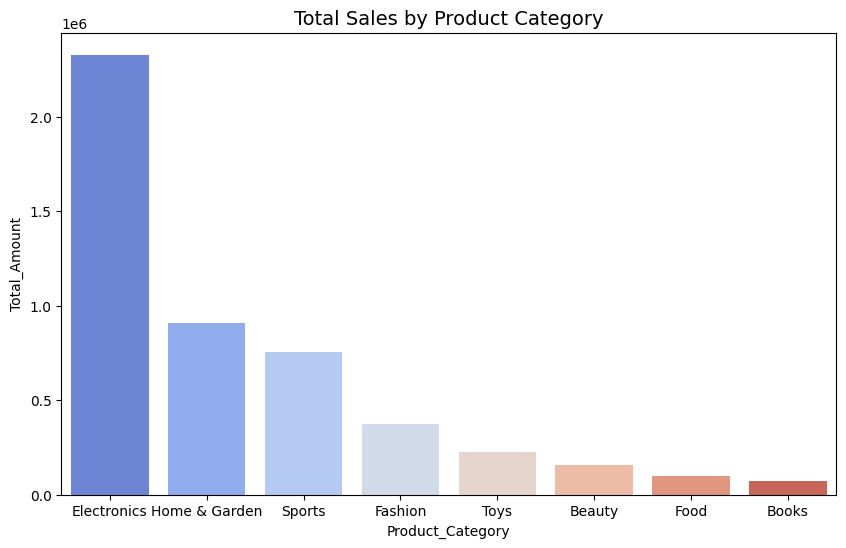

In [32]:
plt.figure(figsize=(10,6))
sns.barplot(x=Salesby_cate.index,y=Salesby_cate,palette="coolwarm")
plt.title("Total Sales by Product Category", fontsize=14)
plt.xlabel=("Product Category")
plt.ylabel=("Total Sales (USD)")
plt.show()

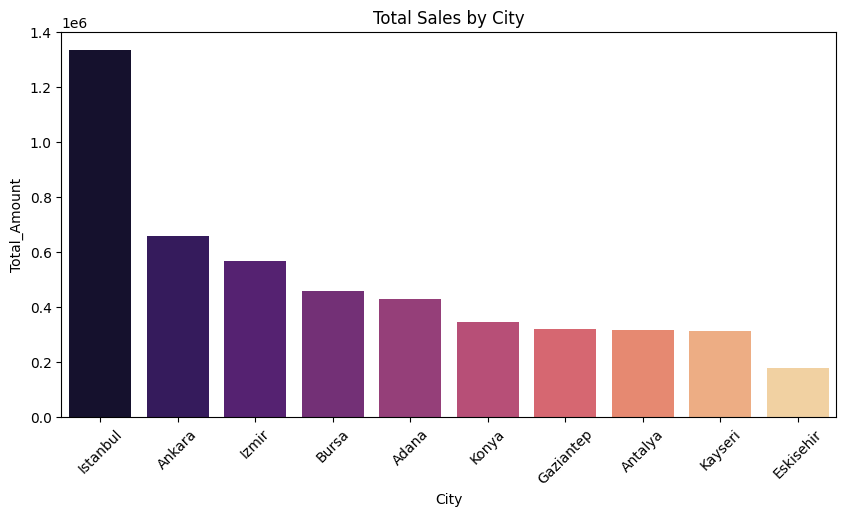

In [33]:
sales_by_city=df.groupby("City")["Total_Amount"].sum().sort_values(ascending=False)
plt.figure(figsize=(10,5))
sns.barplot(x=sales_by_city.index,y=sales_by_city,palette="magma")
plt.title("Total Sales by City")
plt.xticks(rotation=45)
plt.show()

TypeError: 'str' object is not callable

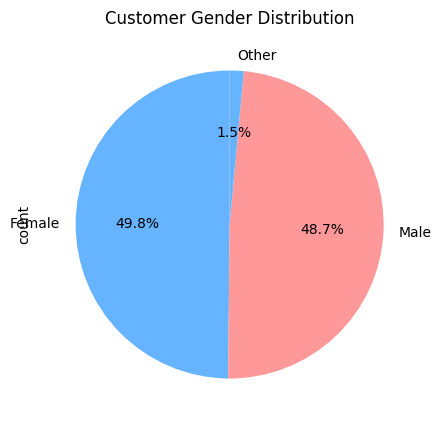

In [34]:
plt.figure(figsize=(5,5))
df["Gender"].value_counts().plot.pie(autopct='%1.1f%%', colors=["#66b3ff","#ff9999"], startangle=90)
plt.title("Customer Gender Distribution")
plt.ylabel("")
plt.show()

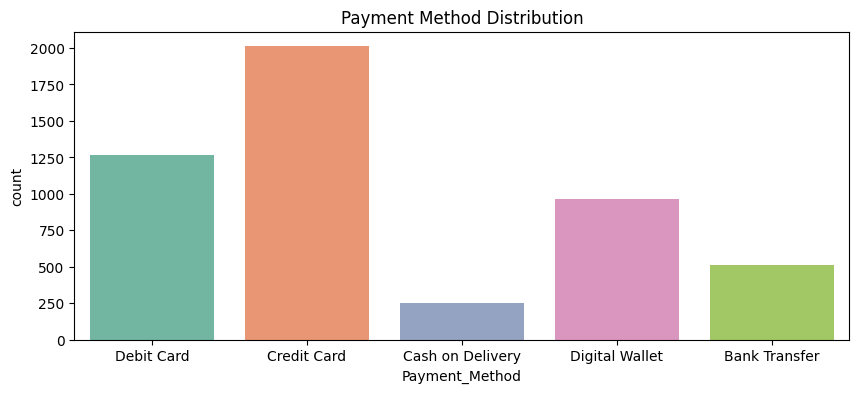

In [36]:
plt.figure(figsize=(10,4))
sns.countplot(data=df, x="Payment_Method", palette="Set2")
plt.title("Payment Method Distribution")
plt.show()

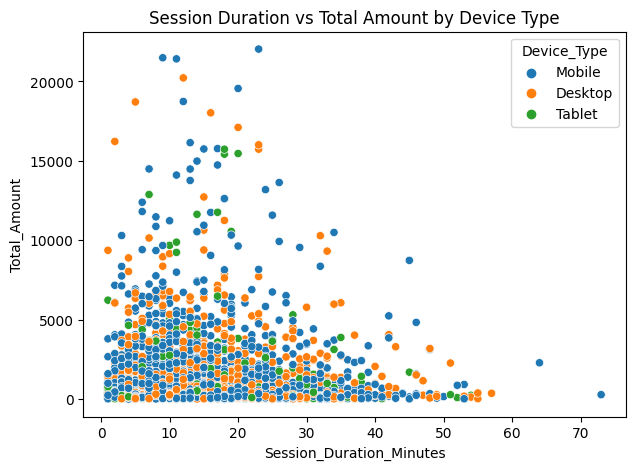

In [37]:
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x="Session_Duration_Minutes", y="Total_Amount", hue="Device_Type")
plt.title("Session Duration vs Total Amount by Device Type")
plt.show()